# Lesson 2 — The score and the sigmoid

Lesson 2 — The score and the sigmoid
=====================================

GURU NOTE
---------
We have features (Lesson 1). Now Move 2: a formula with knobs that turns those
features into a guess. For logistic regression — your `xorguard-supervised-v1`
model — the formula is astonishingly simple, just two steps:

  1. WEIGHTED SUM:   z = w1*x1 + w2*x2 + ... + wD*xD        (a raw "score")
  2. SQUASH:         p = sigmoid(z) = 1 / (1 + e^-z)        (a probability 0..1)

That's the entire model. `predict_proba` in train.py is literally
`sigmoid(x @ weights)` — one line. This lesson makes both steps concrete, and
introduces the "bias trick" that explains why the LAST feature in your repo is
always 1.0.

Run me:  python lessons/lesson_02_score_and_sigmoid.py

## Setup

These notebooks *import* the real code from `lessons/*.py` — one source of truth, no forked copies. This cell finds that folder.

In [1]:
import sys, pathlib
for base in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (base / 'lessons' / '_util.py').exists():
        sys.path.insert(0, str(base / 'lessons'))
        print('lessons on path:', base / 'lessons'); break
else:
    raise RuntimeError('Open this notebook inside the xorguard-ml-course folder.')

lessons on path: /Users/anil/Documents/developer/vscodeworkspaces/xordev/xorguard-ml-course/lessons


## The key code (shown live from the source file)

Read it, then copy any function into a new cell and tweak it — the originals live in `lessons/lesson_02_score_and_sigmoid.py`.

In [2]:
import inspect
from lesson_02_score_and_sigmoid import sigmoid, add_bias, predict_proba
for fn in (sigmoid, add_bias, predict_proba):
    print(inspect.getsource(fn)); print('-' * 72)

def sigmoid(z):
    """Squash any real number into (0, 1). Same as train.sigmoid in the repo.

    The np.clip guards against overflow: e^1000 is infinity in floating point,
    but sigmoid(1000) is 1.0 for all practical purposes, so clipping at +-30 is a
    safe no-op. This exact trick is in the real code.
    """
    return 1.0 / (1.0 + np.exp(-np.clip(z, -30.0, 30.0)))

------------------------------------------------------------------------
def add_bias(X):
    """The BIAS TRICK.

    A model needs a baseline — a constant it can add regardless of the features
    ("how suspicious am I before seeing any evidence?"). Instead of tracking that
    constant separately, we glue a column of 1.0s onto X. Then its weight behaves
    like any other weight, and z = w . x already includes the baseline.

    This is why your repo's 32nd feature is 'bias' and is always 1.0.
    """
    ones = np.ones((X.shape[0], 1))
    return np.concatenate([X, ones], axis=1)

--------------------------------

## A picture

A real plot (matplotlib) in place of the terminal's ASCII. Re-run after changing inputs to build intuition.

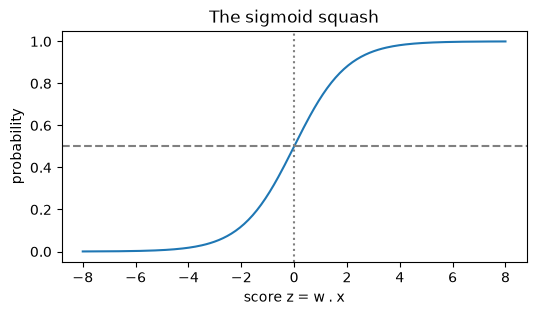

In [3]:
import numpy as np, matplotlib.pyplot as plt
from lesson_02_score_and_sigmoid import sigmoid
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 3)); plt.plot(z, sigmoid(z))
plt.axhline(0.5, ls='--', c='gray'); plt.axvline(0, ls=':', c='gray')
plt.xlabel('score z = w . x'); plt.ylabel('probability'); plt.title('The sigmoid squash')
plt.show()

## Run the full narrated lesson

This executes the same walkthrough as `python lessons/lesson_02_score_and_sigmoid.py`, printing each step with its result.

In [4]:
from lesson_02_score_and_sigmoid import main
main()


════════════════════════════════════
Lesson 2 — The score and the sigmoid
════════════════════════════════════

▸ Meet the sigmoid. It turns a raw score into a probability.
    Very negative score -> ~0 (surely benign)
    Score of 0          -> exactly 0.5 (no idea)
    Very positive score -> ~1 (surely malicious)

  sigmoid(z):  z on x-axis, probability on y-axis
                                       ••••••••••••••••••••
                                    •••                    
                                  ••                       
                                 •                         
                                •                          
                              ••                           
                             •                             
                            •                              
                          ••                               
                       •••                                 
    •••••••••••••••••••        

## Exercises

Try these in new cells below. Worked answers are in `solutions/lesson_02_solution.py`.

```
1. Make the model STRICTER (fewer attacks slip through, but more false alarms)
   by changing ONE number in w. Which one, and which direction? Verify by
   re-running and watching accuracy + which strings flip.

2. What weights make the model predict 0.5 for EVERYTHING regardless of input?
   (Hint: think about what makes z always 0.)

3. Compute z by hand (no sigmoid) for "' OR 1=1--" with the weights above.
   Then confirm sigmoid(z) matches what predict_proba prints.
```

In [5]:
# your work here
